<a href="https://colab.research.google.com/github/Novi-Aji-Sukmanto/Praktikum-Struktur-Data-Dan-Algoritma/blob/main/Kel4_TB_Grafik_Visualisasi_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

,Bulan,Pengguna Aktif
0,Jan,1200
1,Feb,1500
2,Mar,1800
3,Apr,2200
4,Mei,2600
5,Jun,3000


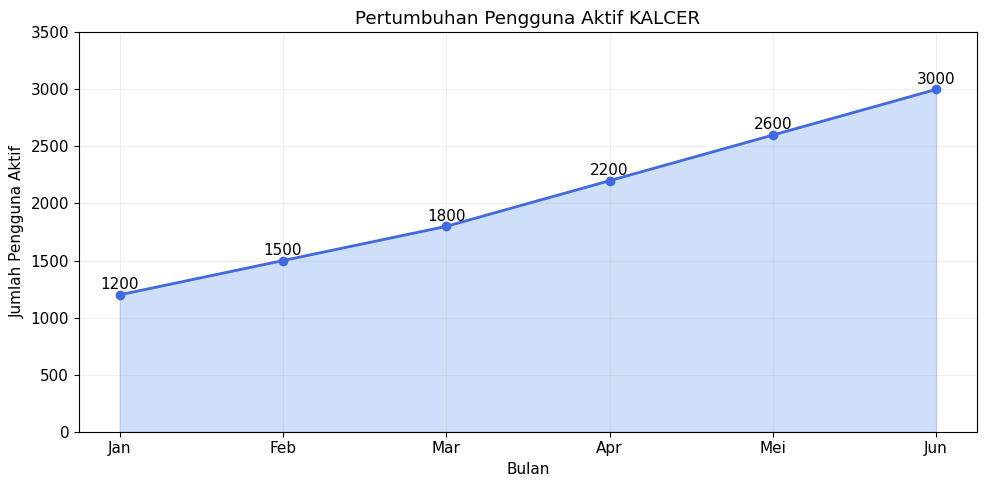

,Bulan,Pengguna Aktif,Pertumbuhan
0,Jan,1200,NaN
1,Feb,1500,300.0
2,Mar,1800,300.0
3,Apr,2200,400.0
4,Mei,2600,400.0
5,Jun,3000,400.0


In [ ]:

# SOAL 1 - AREA CHART
import pandas as pd
import matplotlib.pyplot as plt

data_kalcer = {
    'Bulan': ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun'],
    'Pengguna Aktif': [1200, 1500, 1800, 2200, 2600, 3000]
}

df_kalcer = pd.DataFrame(data_kalcer)
display(df_kalcer)

plt.figure(figsize=(10, 5))
plt.plot(df_kalcer['Bulan'], df_kalcer['Pengguna Aktif'],
         color='royalblue', marker='o', linewidth=2)

plt.fill_between(
    df_kalcer['Bulan'],
    df_kalcer['Pengguna Aktif'],
    color='cornflowerblue',
    alpha=0.3
)

for i, nilai in enumerate(df_kalcer['Pengguna Aktif']):
    plt.text(i, nilai + 50, str(nilai), ha='center')

plt.title('Pertumbuhan Pengguna Aktif KALCER')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Pengguna Aktif')
plt.ylim(0, 3500)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('soal1_area_chart.png', dpi=300)
plt.show()

# Menghitung pertumbuhan bulanan
df_kalcer['Pertumbuhan'] = (
    df_kalcer['Pengguna Aktif'].diff()
)
display(df_kalcer)


,Produk,Jumlah Terjual
0,Tas,120
1,Sepatu,200
2,Jaket,150
3,Topi,90
4,Kaos,250


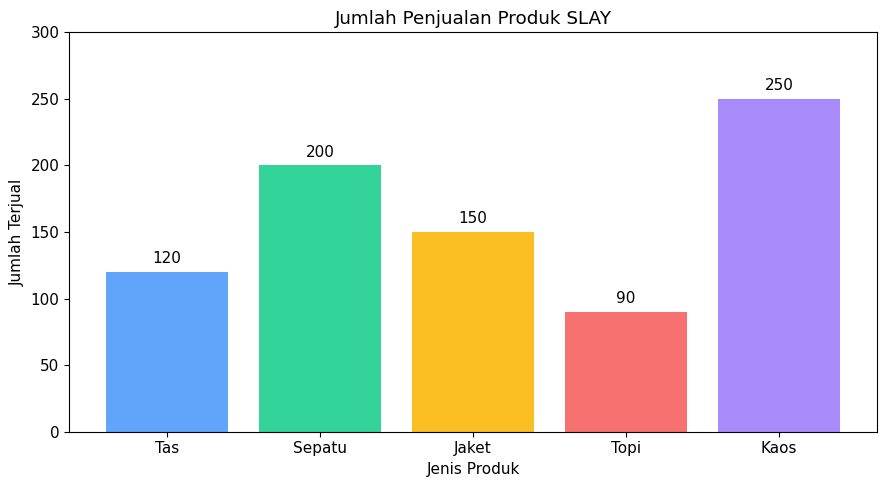

In [ ]:

# SOAL 2 - BAR CHART
import pandas as pd
import matplotlib.pyplot as plt

df_slay = pd.DataFrame({
    'Produk': ['Tas', 'Sepatu', 'Jaket', 'Topi', 'Kaos'],
    'Jumlah Terjual': [120, 200, 150, 90, 250]
})

display(df_slay)

plt.figure(figsize=(9, 5))
bars = plt.bar(
    df_slay['Produk'],
    df_slay['Jumlah Terjual'],
    color=['#60A5FA', '#34D399', '#FBBF24',
           '#F87171', '#A78BFA']
)

plt.bar_label(bars, padding=4)
plt.title('Jumlah Penjualan Produk SLAY')
plt.xlabel('Jenis Produk')
plt.ylabel('Jumlah Terjual')
plt.ylim(0, 300)
plt.tight_layout()
plt.savefig('soal2_bar_chart.png', dpi=300)
plt.show()


,Tugas,Mulai,Selesai,Durasi
0,Analisis,2026-01-01,2026-01-05,5
1,Desain UI,2026-01-06,2026-01-10,5
2,Coding,2026-01-11,2026-01-25,15
3,Testing,2026-01-26,2026-01-30,5


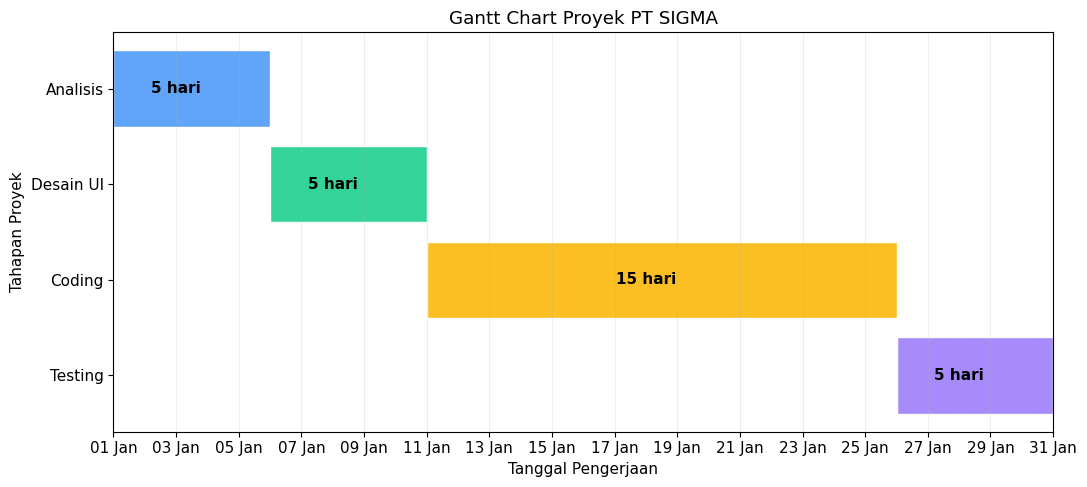

In [ ]:

# SOAL 3 - GANTT CHART
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_sigma = pd.DataFrame({
    'Tugas': ['Analisis', 'Desain UI', 'Coding', 'Testing'],
    'Mulai': ['2026-01-01', '2026-01-06',
              '2026-01-11', '2026-01-26'],
    'Selesai': ['2026-01-05', '2026-01-10',
                '2026-01-25', '2026-01-30']
})

df_sigma['Mulai'] = pd.to_datetime(df_sigma['Mulai'])
df_sigma['Selesai'] = pd.to_datetime(df_sigma['Selesai'])

# Durasi inklusif: tanggal awal dan akhir dihitung
df_sigma['Durasi'] = (
    df_sigma['Selesai'] - df_sigma['Mulai']
).dt.days + 1

display(df_sigma)

fig, ax = plt.subplots(figsize=(11, 5))
warna = ['#60A5FA', '#34D399', '#FBBF24', '#A78BFA']

for i, row in df_sigma.iterrows():
    ax.barh(
        row['Tugas'],
        row['Durasi'],
        left=mdates.date2num(row['Mulai']),
        color=warna[i],
        edgecolor='white'
    )

    tengah = row['Mulai'] + (
        row['Selesai'] - row['Mulai']
    ) / 2

    ax.text(tengah, i, f"{row['Durasi']} hari",
            ha='center', va='center', fontweight='bold')

ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_formatter(
    mdates.DateFormatter('%d %b')
)
ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=2)
)
ax.set_xlim(pd.Timestamp('2026-01-01'),
            pd.Timestamp('2026-01-31'))
ax.set_title('Gantt Chart Proyek PT SIGMA')
ax.set_xlabel('Tanggal Pengerjaan')
ax.set_ylabel('Tahapan Proyek')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.savefig('soal3_gantt_chart.png', dpi=300)
plt.show()


,Nilai UTS
0,55
1,60
2,65
3,70
4,75
5,80
6,85
7,90
8,75
9,70


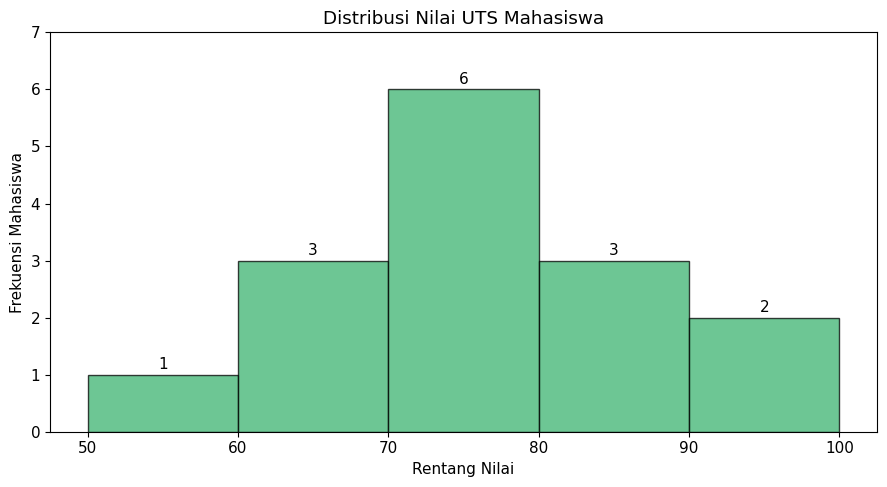

Rata-rata: 74.87
Modus: [70, 75]
Skewness: -0.045


In [ ]:

# SOAL 4 - HISTOGRAM
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

nilai = [55, 60, 65, 70, 75, 80, 85, 90,
         75, 70, 68, 72, 88, 92, 78]

df_nilai = pd.DataFrame({'Nilai UTS': nilai})
display(df_nilai)

bins = [50, 60, 70, 80, 90, 100]

plt.figure(figsize=(9, 5))
frekuensi, batas, patches = plt.hist(
    df_nilai['Nilai UTS'],
    bins=bins,
    color='mediumseagreen',
    edgecolor='black',
    alpha=0.75
)

for i, jumlah in enumerate(frekuensi):
    tengah = (batas[i] + batas[i+1]) / 2
    plt.text(tengah, jumlah + 0.1,
             str(int(jumlah)), ha='center')

plt.title('Distribusi Nilai UTS Mahasiswa')
plt.xlabel('Rentang Nilai')
plt.ylabel('Frekuensi Mahasiswa')
plt.xticks(bins)
plt.ylim(0, max(frekuensi) + 1)
plt.tight_layout()
plt.savefig('soal4_histogram.png', dpi=300)
plt.show()

print('Rata-rata:', round(np.mean(nilai), 2))
print('Modus:', df_nilai['Nilai UTS'].mode().tolist())
print('Skewness:', round(df_nilai['Nilai UTS'].skew(), 3))


,Hari,Penjualan
0,Senin,100
1,Selasa,120
2,Rabu,90
3,Kamis,150
4,Jumat,200
5,Sabtu,250
6,Minggu,300


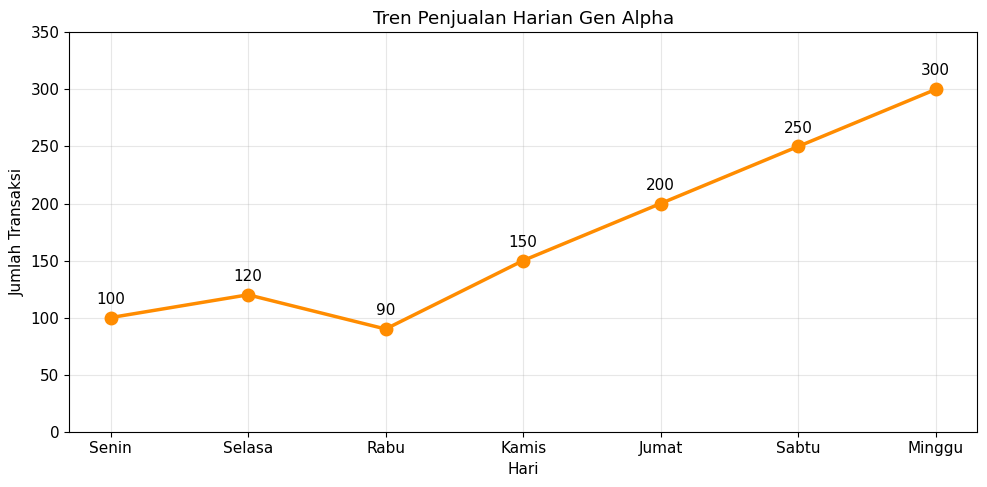

In [ ]:

# SOAL 5 - LINE CHART
import pandas as pd
import matplotlib.pyplot as plt

df_genalpha = pd.DataFrame({
    'Hari': ['Senin', 'Selasa', 'Rabu', 'Kamis',
             'Jumat', 'Sabtu', 'Minggu'],
    'Penjualan': [100, 120, 90, 150, 200, 250, 300]
})

display(df_genalpha)

plt.figure(figsize=(10, 5))
plt.plot(
    df_genalpha['Hari'],
    df_genalpha['Penjualan'],
    color='darkorange',
    marker='o',
    markersize=9,
    linewidth=2.5
)

for i, nilai in enumerate(df_genalpha['Penjualan']):
    plt.annotate(
        str(nilai), (i, nilai),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center'
    )

plt.title('Tren Penjualan Harian Gen Alpha')
plt.xlabel('Hari')
plt.ylabel('Jumlah Transaksi')
plt.ylim(0, 350)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('soal5_line_chart.png', dpi=300)
plt.show()


/tmp/ipykernel_2428/151741725.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


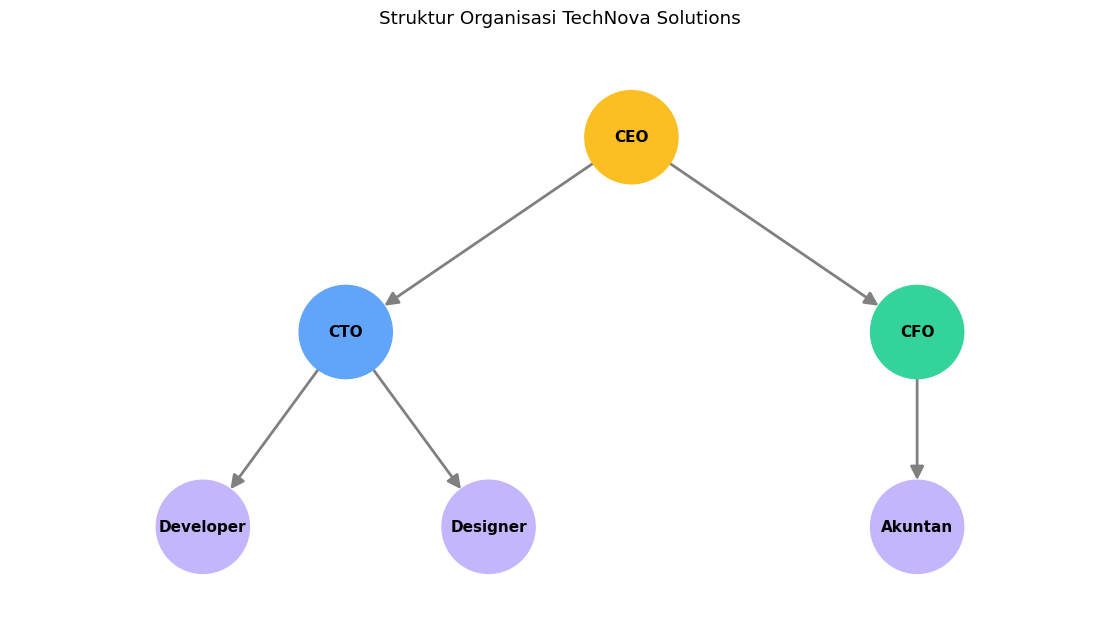

In [ ]:

# SOAL 6 - TREE DIAGRAM
import matplotlib.pyplot as plt
import networkx as nx

G = nx.DiGraph()

hubungan = [
    ('CEO', 'CTO'),
    ('CEO', 'CFO'),
    ('CTO', 'Developer'),
    ('CTO', 'Designer'),
    ('CFO', 'Akuntan')
]

G.add_edges_from(hubungan)

pos = {
    'CEO': (0, 3),
    'CTO': (-2, 2),
    'CFO': (2, 2),
    'Developer': (-3, 1),
    'Designer': (-1, 1),
    'Akuntan': (2, 1)
}

plt.figure(figsize=(11, 6))
nx.draw(
    G, pos,
    with_labels=True,
    node_size=4500,
    node_color=['#FBBF24', '#60A5FA', '#34D399',
                '#C4B5FD', '#C4B5FD', '#C4B5FD'],
    font_size=11,
    font_weight='bold',
    arrows=True,
    arrowsize=20,
    edge_color='gray',
    width=2
)

plt.title('Struktur Organisasi TechNova Solutions')
plt.margins(0.2)
plt.tight_layout()
plt.savefig('soal6_tree_diagram.png', dpi=300)
plt.show()


In [ ]:

# Simpan dataset menjadi CSV
df_kalcer.to_csv('dataset_kalcer.csv', index=False)
df_slay.to_csv('dataset_slay.csv', index=False)
df_sigma.to_csv('dataset_sigma.csv', index=False)
df_nilai.to_csv('dataset_nilai.csv', index=False)
df_genalpha.to_csv('dataset_genalpha.csv', index=False)

# Gabungkan grafik dan dataset menjadi ZIP
import zipfile
from google.colab import files

nama_file = [
    'soal1_area_chart.png',
    'soal2_bar_chart.png',
    'soal3_gantt_chart.png',
    'soal4_histogram.png',
    'soal5_line_chart.png',
    'soal6_tree_diagram.png',
    'dataset_kalcer.csv',
    'dataset_slay.csv',
    'dataset_sigma.csv',
    'dataset_nilai.csv',
    'dataset_genalpha.csv'
]

with zipfile.ZipFile('Tugas_Besar_Visualisasi.zip', 'w') as zipf:
    for nama in nama_file:
        zipf.write(nama)

files.download('Tugas_Besar_Visualisasi.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>